In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/santhoshkumarpuppala/american-bankruptcy-data/american_bankruptcy_dataset.csv


In [2]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv(r"/kaggle/input/datasets/santhoshkumarpuppala/american-bankruptcy-data/american_bankruptcy_dataset.csv")
pd.set_option('display.max_columns',None)

In [4]:
df.shape

(78682, 23)

In [5]:
df.rename(columns={
    "X1": "Current_Assets",
    "X2": "Cost_of_Goods_Sold",
    "X3": "Depreciation_and_Amortization",
    "X4": "EBITDA",
    "X5": "Inventory",
    "X6": "Net_Income",
    "X7": "Total_Receivables",
    "X8": "Market_Value",
    "X9": "Net_Sales",
    "X10": "Total_Assets",
    "X11": "Long_Term_Debt",
    "X12": "EBIT",
    "X13": "Gross_Profit",
    "X14": "Current_Liabilities",
    "X15": "Retained_Earnings",
    "X16": "Total_Revenue",
    "X17": "Total_Liabilities",
    "X18": "Operating_Expenses"}, inplace=True)

In [6]:
df.isna().sum()

company_name                     0
fyear                            0
status_label                     0
Current_Assets                   0
Cost_of_Goods_Sold               0
Depreciation_and_Amortization    0
EBITDA                           0
Inventory                        0
Net_Income                       0
Total_Receivables                0
Market_Value                     0
Net_Sales                        0
Total_Assets                     0
Long_Term_Debt                   0
EBIT                             0
Gross_Profit                     0
Current_Liabilities              0
Retained_Earnings                0
Total_Revenue                    0
Total_Liabilities                0
Operating_Expenses               0
Division                         0
MajorGroup                       0
dtype: int64

count    8971.000000
mean        8.770706
std         6.421565
min         1.000000
25%         3.000000
50%         7.000000
75%        14.000000
max        20.000000
Name: fyear, dtype: float64


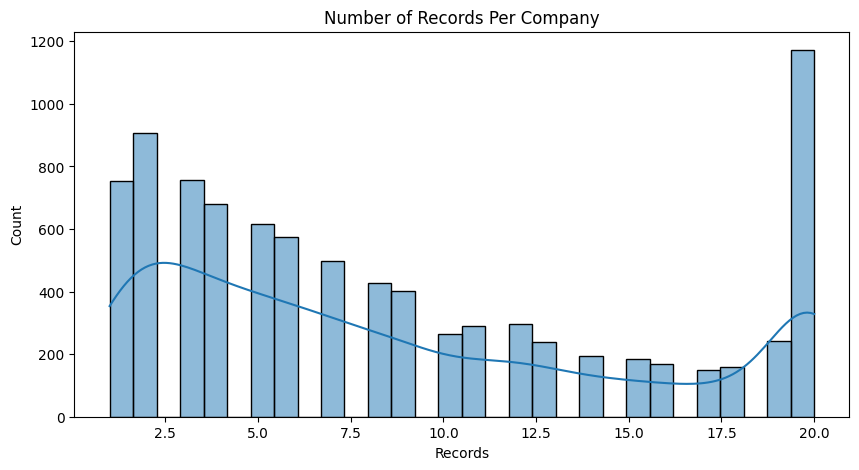

In [7]:
company_counts = df.groupby('company_name')['fyear'].count()

print(company_counts.describe())

plt.figure(figsize=(10,5))
sns.histplot(company_counts, bins=30, kde=True)
plt.title('Number of Records Per Company')
plt.xlabel('Records')
plt.show()

In [8]:
numeric_data  = df.select_dtypes(include=np.number)

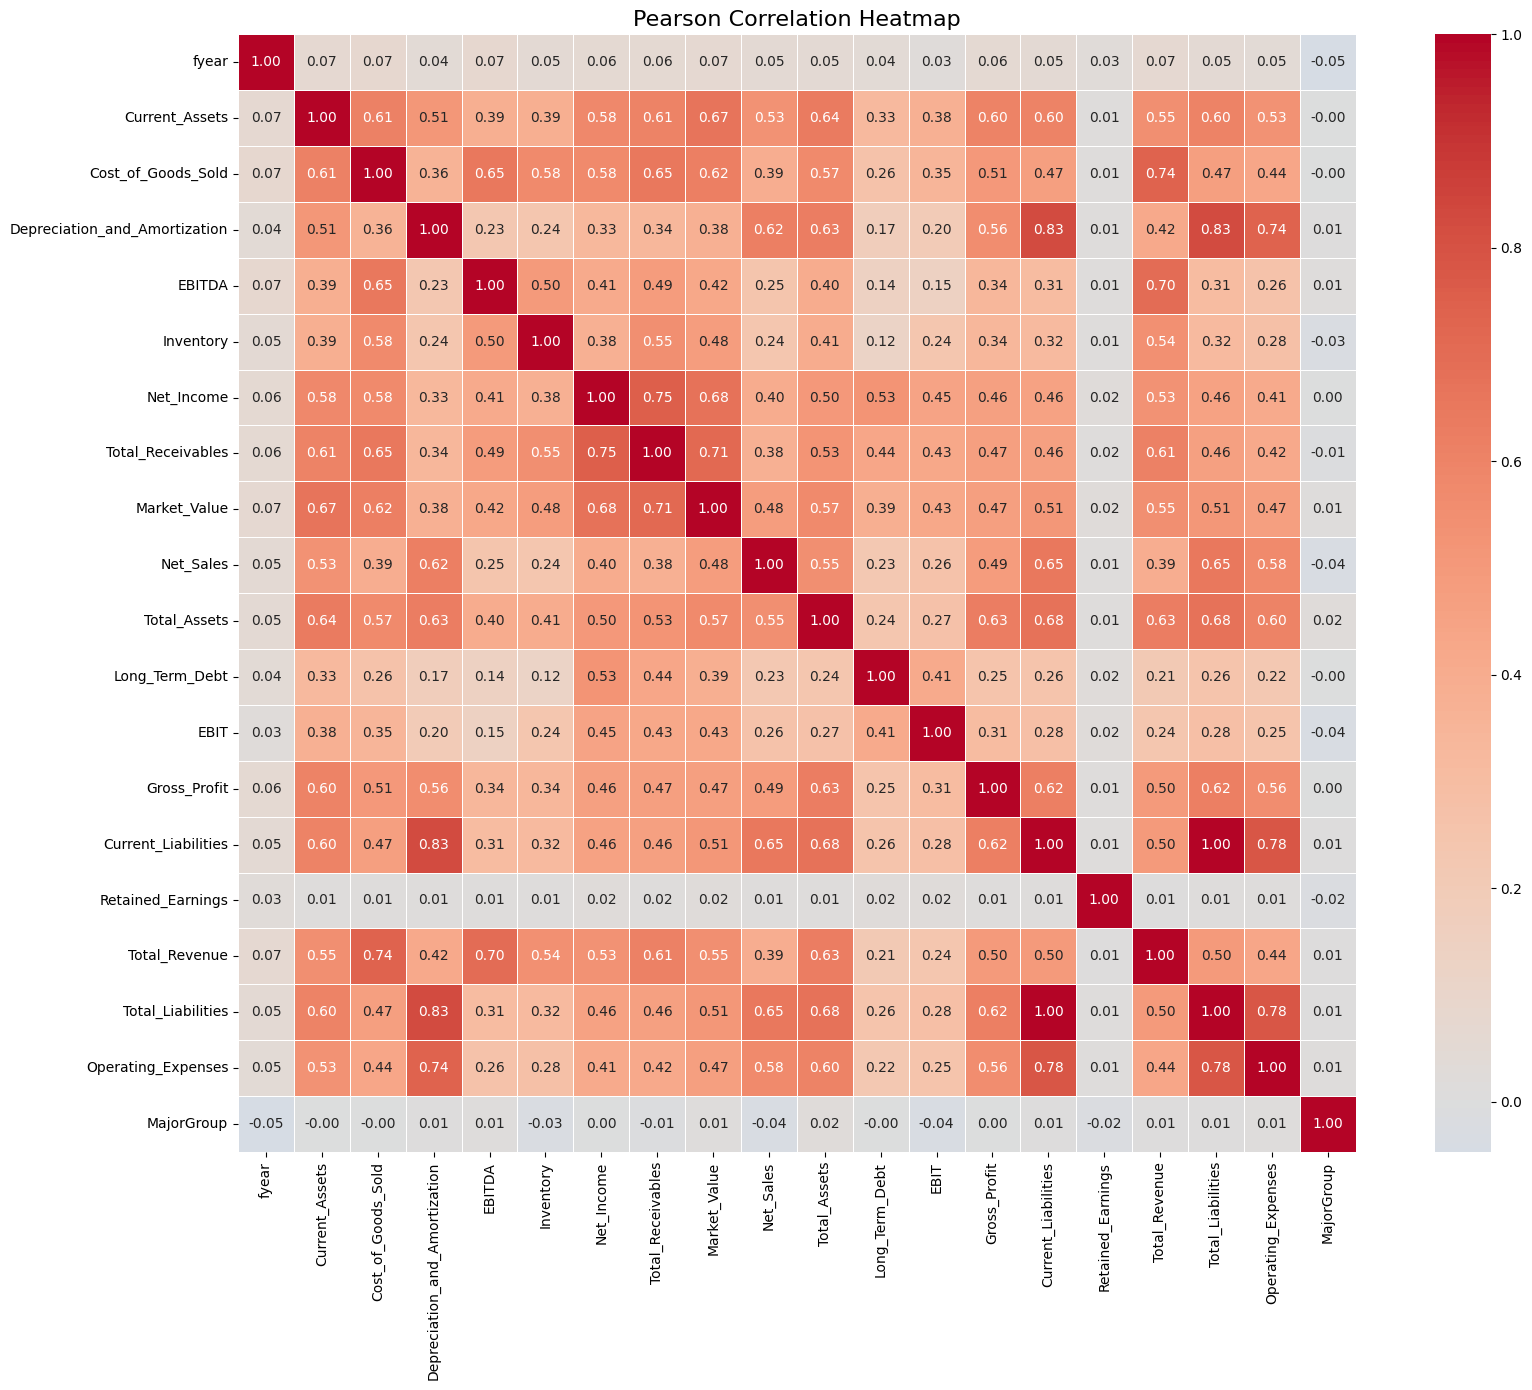

In [9]:
corr_matrix = numeric_data.corr(method="pearson")
plt.figure(figsize=(18, 14))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f",center=0,linewidths=0.5,square=True)
plt.title("Pearson Correlation Heatmap",fontsize=16)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

The correlation heatmap tells
+ Even though there are some columns have very less correlation in the financial aspect those are some important factors to calculte we can retain those features because the ANN can understand the no-linear patterns
  
Current Assets: approximately -0.03.
Net Income: approximately -0.03.
Total Assets: approximately -0.01.

+ some features such as the current laibilities and the total laibilities have the highest correlation after the inspection I have droped the Total laibilities column because they both produce same information to us.



In [10]:
df.columns

Index(['company_name', 'fyear', 'status_label', 'Current_Assets',
       'Cost_of_Goods_Sold', 'Depreciation_and_Amortization', 'EBITDA',
       'Inventory', 'Net_Income', 'Total_Receivables', 'Market_Value',
       'Net_Sales', 'Total_Assets', 'Long_Term_Debt', 'EBIT', 'Gross_Profit',
       'Current_Liabilities', 'Retained_Earnings', 'Total_Revenue',
       'Total_Liabilities', 'Operating_Expenses', 'Division', 'MajorGroup'],
      dtype='object')

In [11]:
label_map = {'alive': 0, 'failed': 1}

df['status_label'] = df['status_label'].map(label_map)

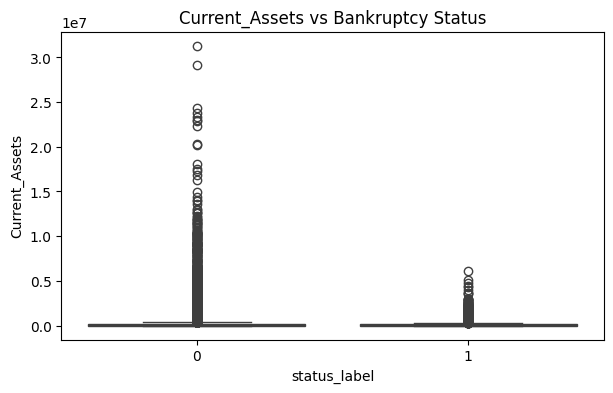

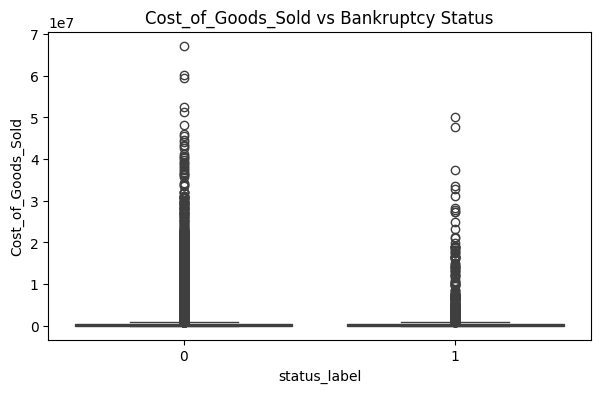

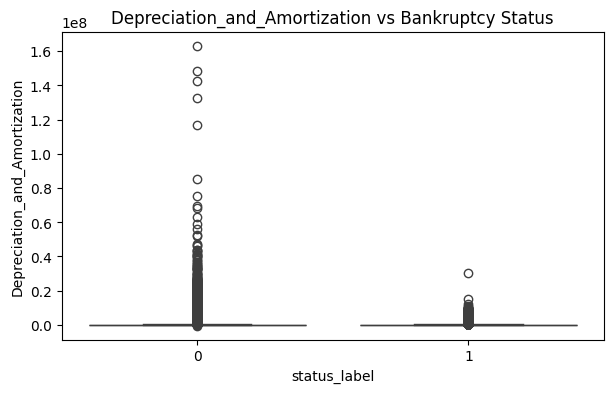

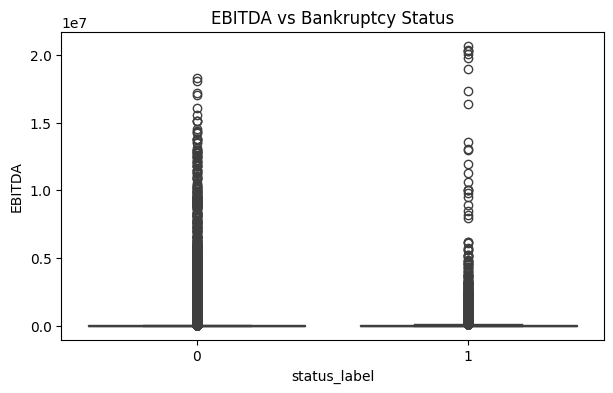

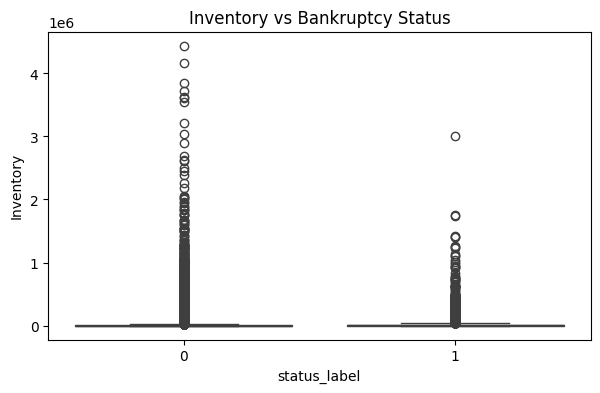

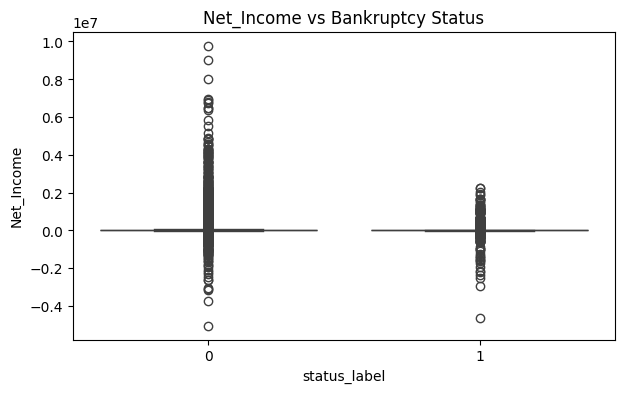

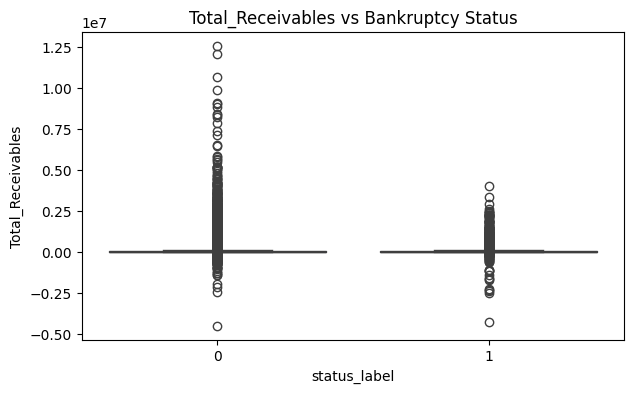

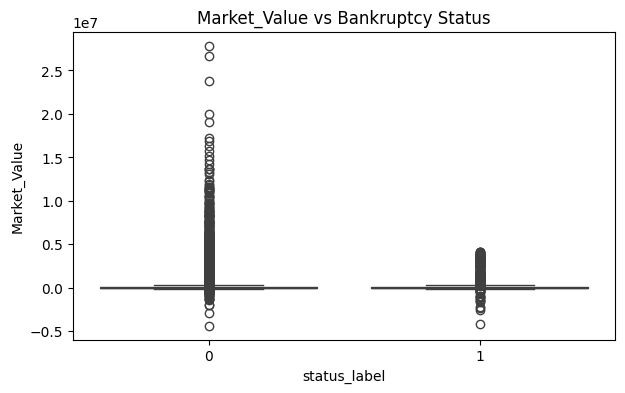

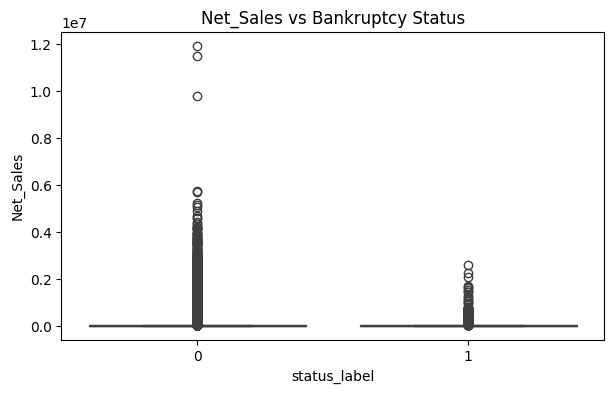

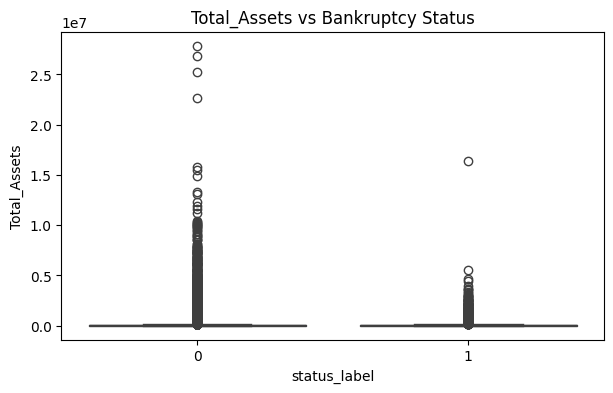

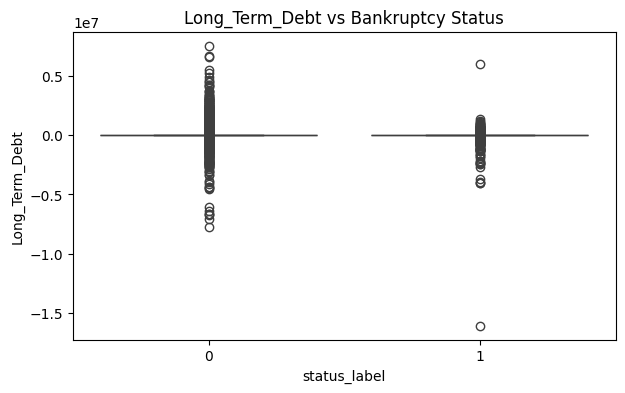

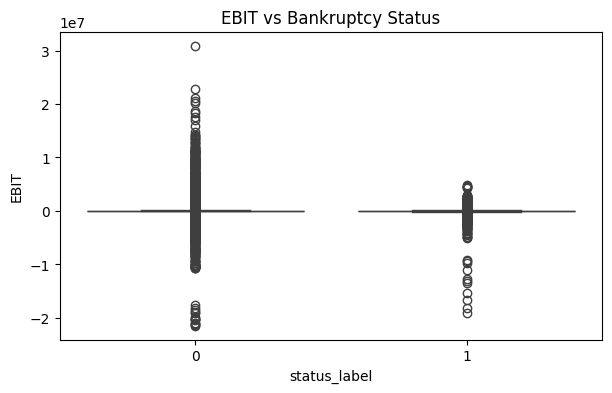

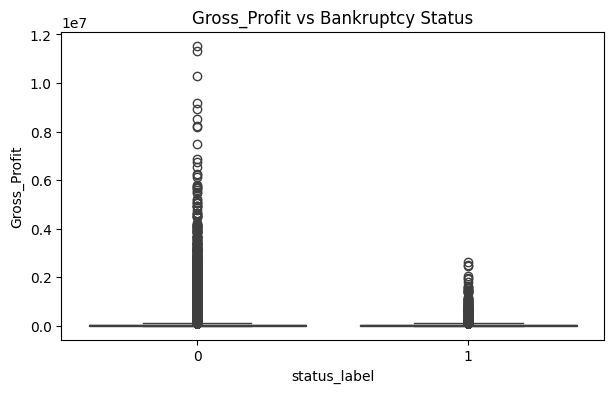

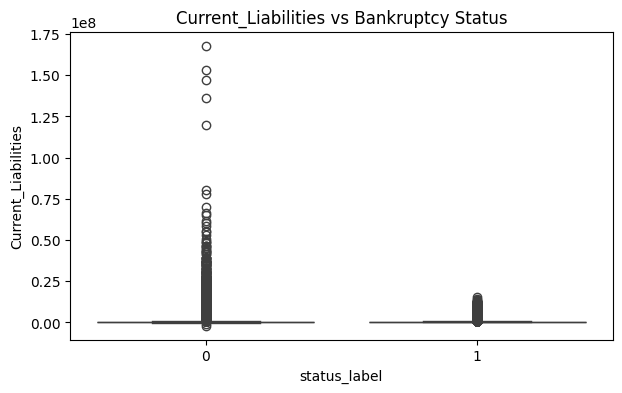

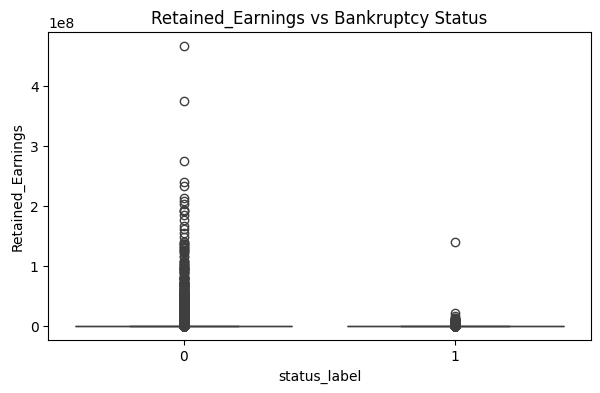

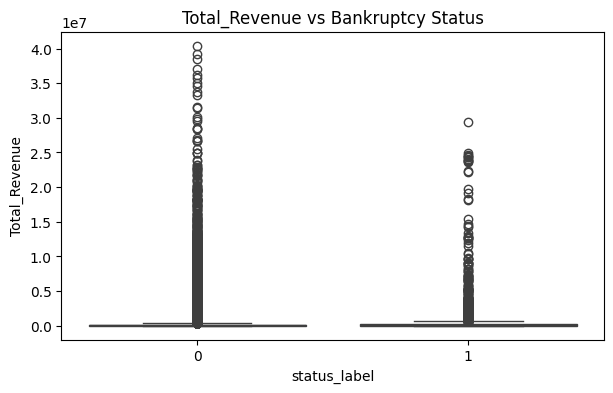

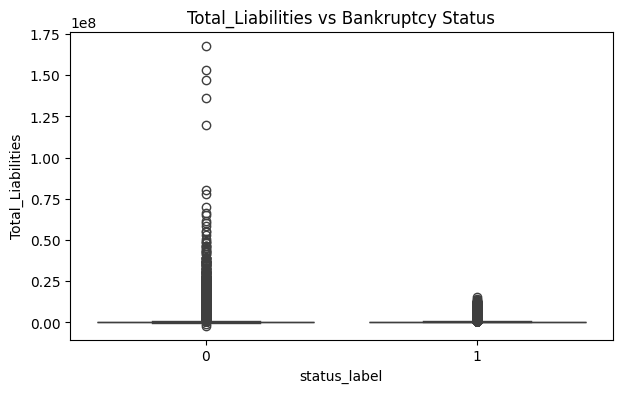

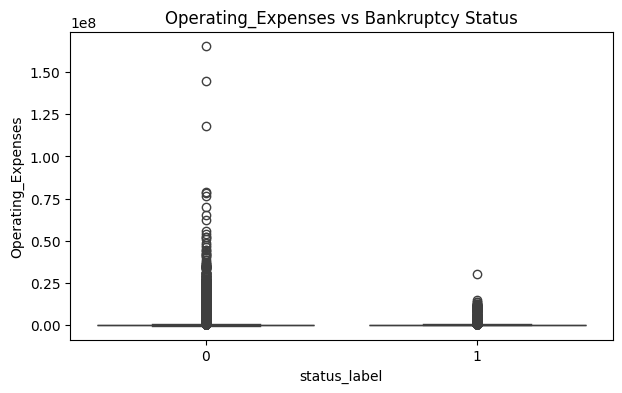

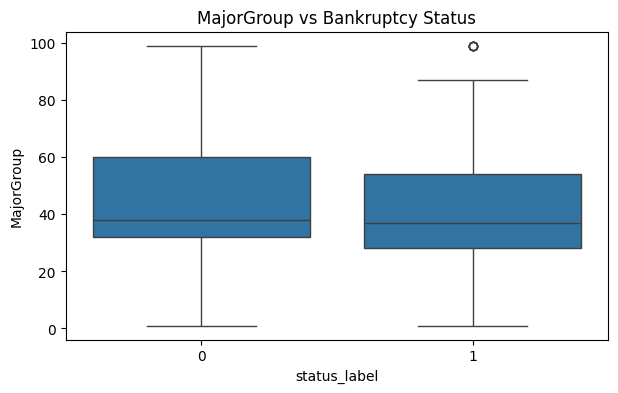

In [12]:
features = df.select_dtypes(include=np.number).columns.drop(['status_label', 'fyear'])

for col in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(data=df,x='status_label',y=col)
    plt.title(f'{col} vs Bankruptcy Status')
    plt.show()

In [ ]:
Even the outliers present in the data set for the financial values are common in the

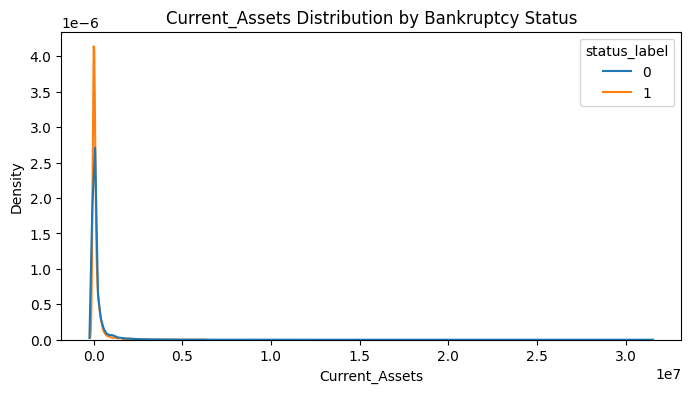

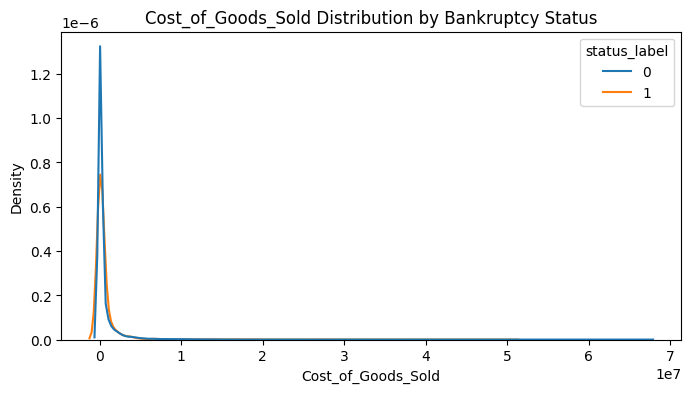

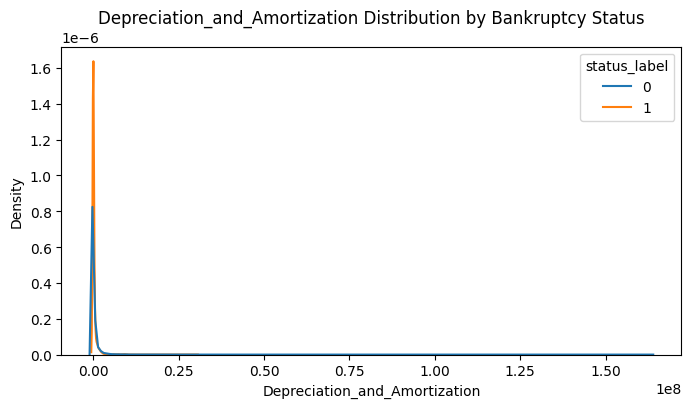

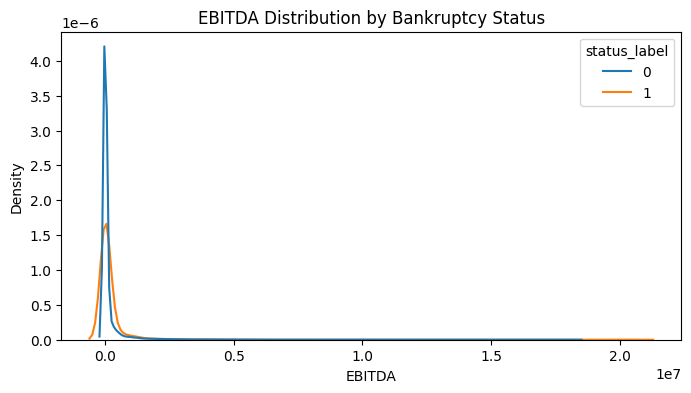

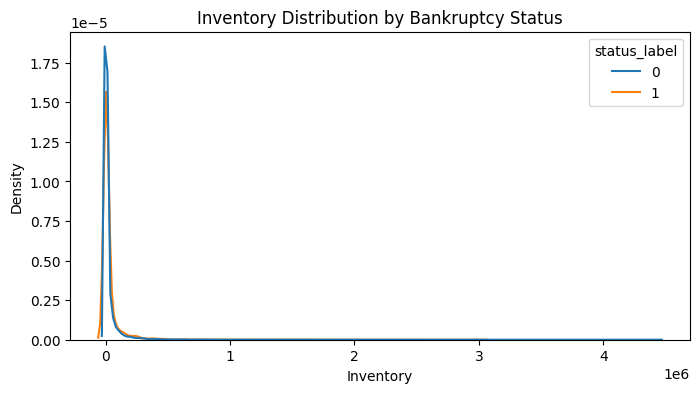

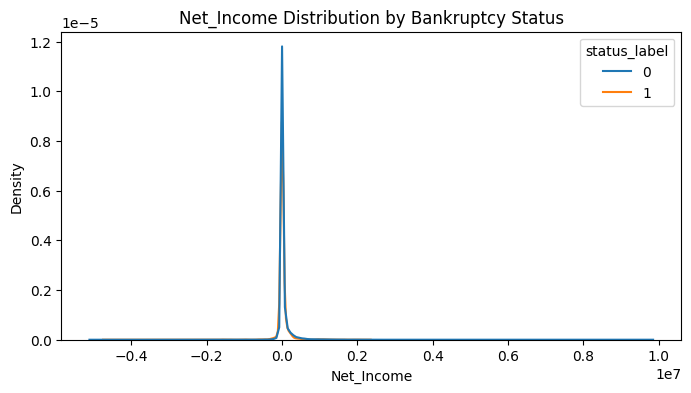

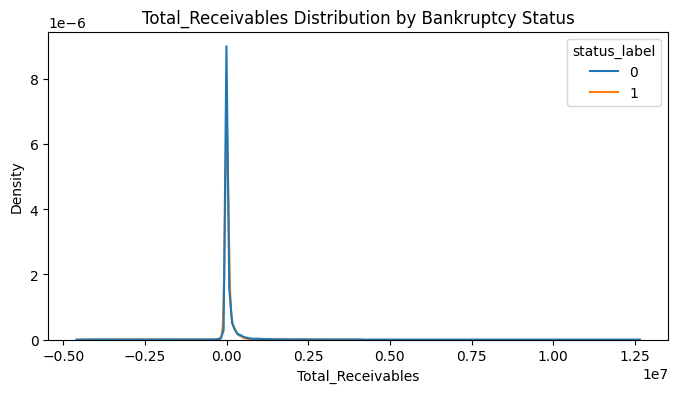

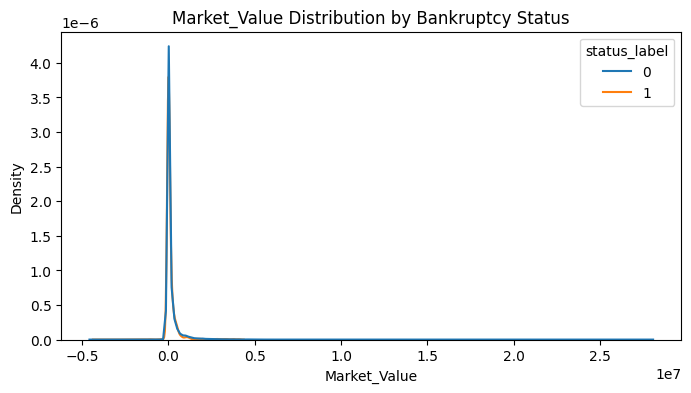

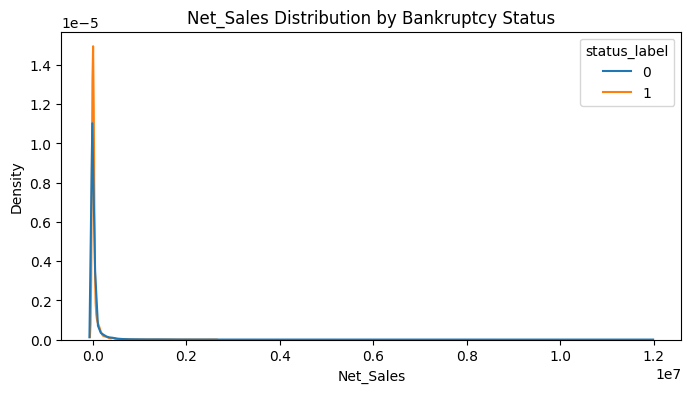

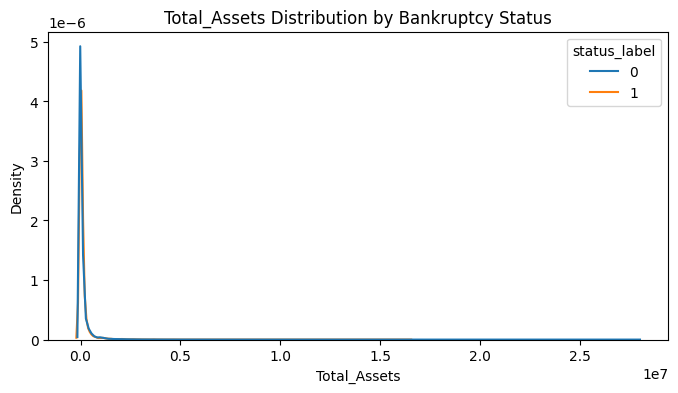

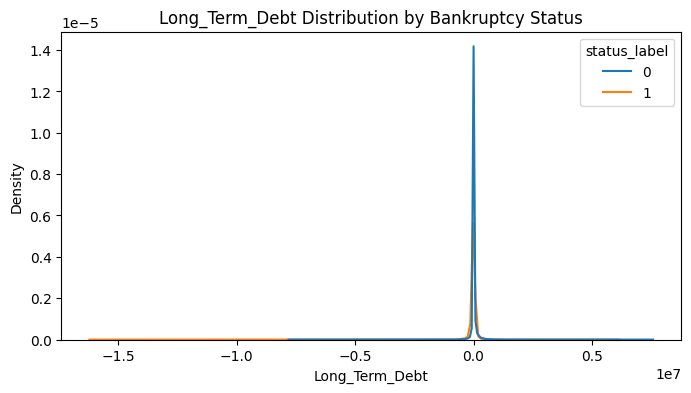

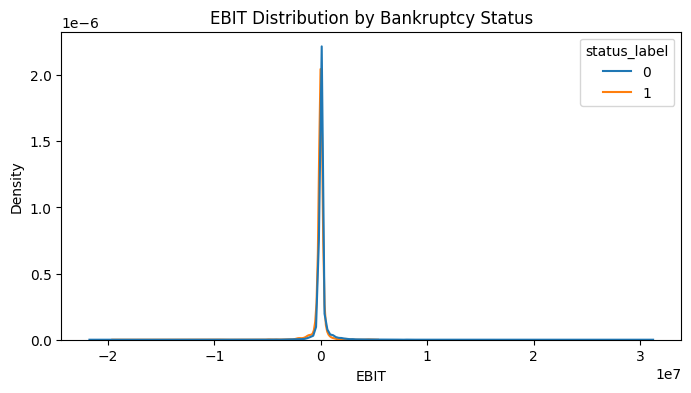

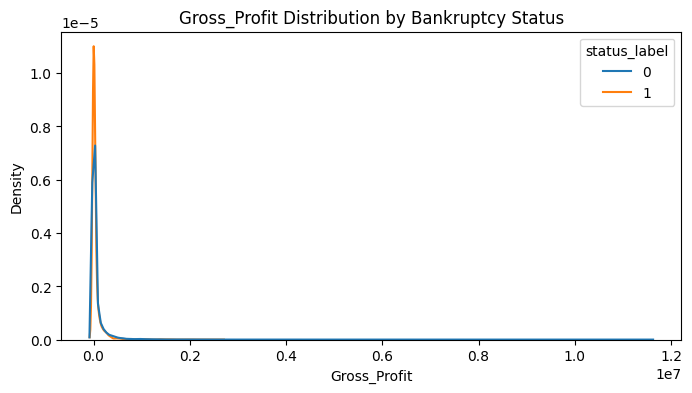

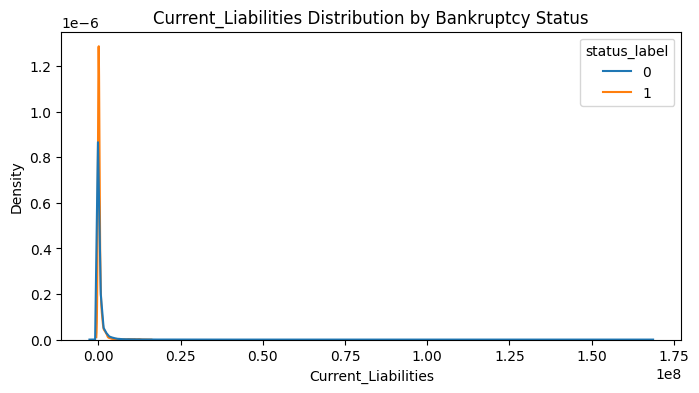

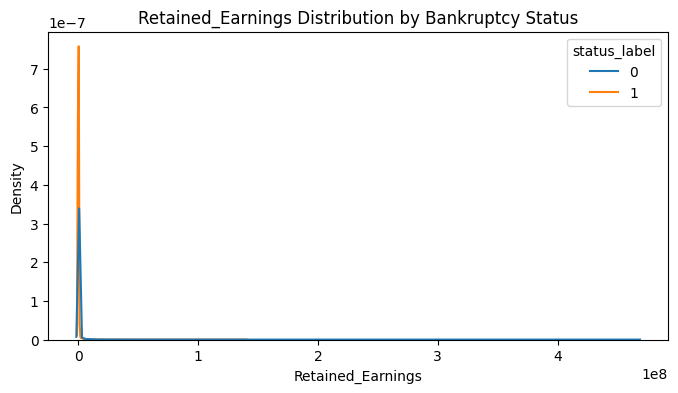

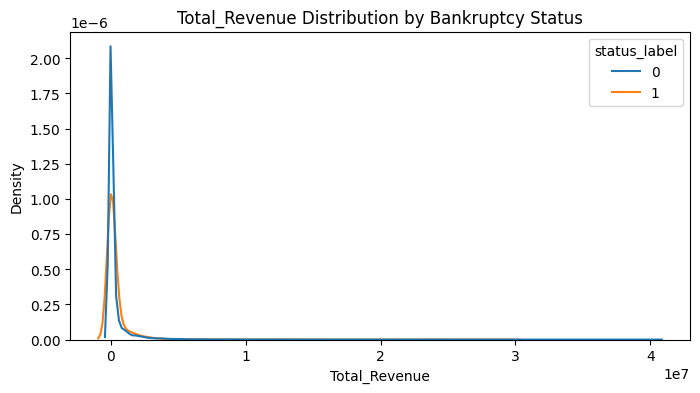

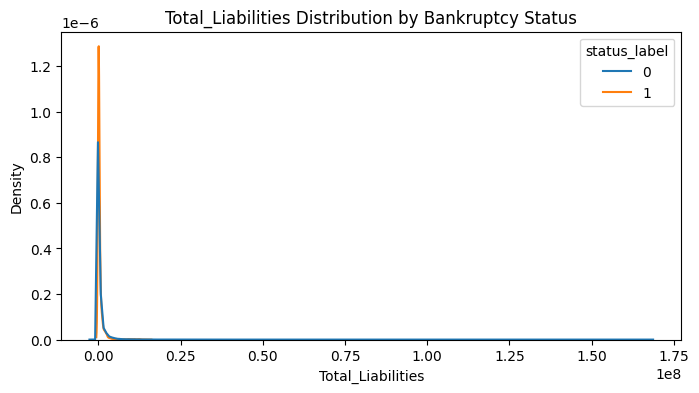

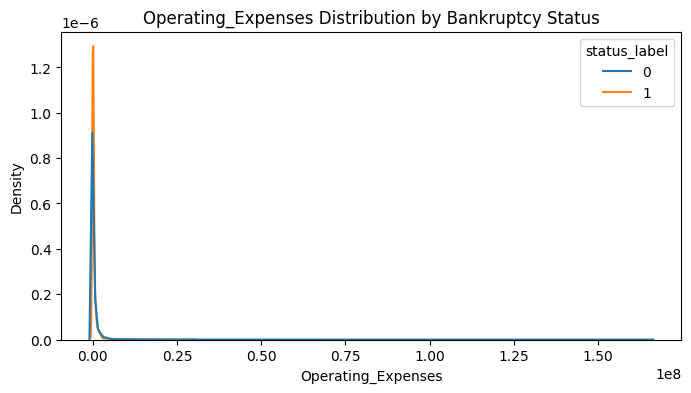

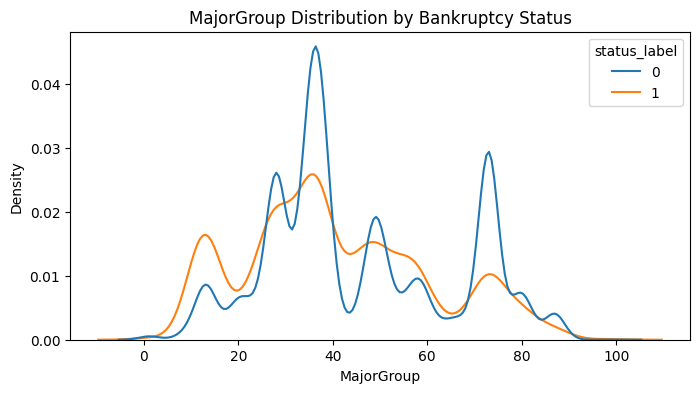

In [13]:
for col in features:
    plt.figure(figsize=(8,4))
    sns.kdeplot(data=df,x=col,hue='status_label',common_norm=False)
    plt.title(f'{col} Distribution by Bankruptcy Status')
    plt.show()

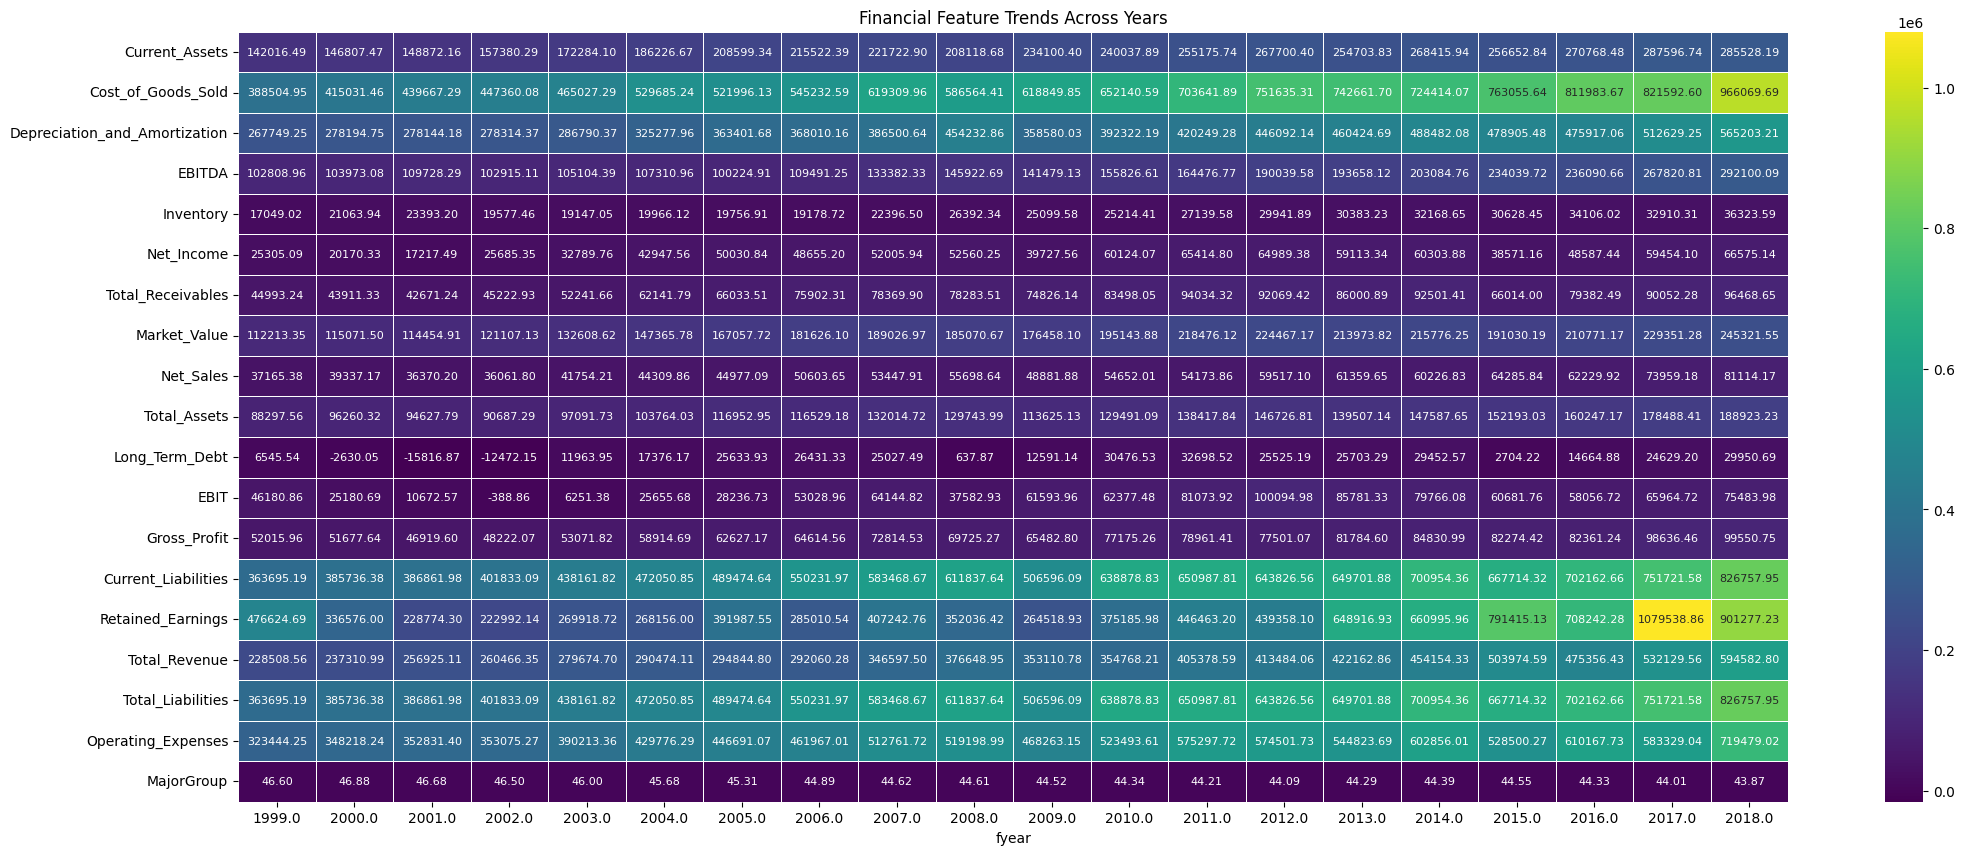

In [14]:

yearly_stats = df.groupby('fyear')[features].mean()
plt.figure(figsize=(25,10))
sns.heatmap(yearly_stats.T,cmap='viridis',annot = True,fmt = ".2f",linewidths = 0.5,annot_kws ={"size":8})
plt.title('Financial Feature Trends Across Years')
plt.show()

In [15]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import StandardScaler

X_vif = df[features].replace(
    [np.inf, -np.inf], np.nan
).dropna()

X_scaled = StandardScaler().fit_transform(X_vif)

vif = pd.DataFrame({
    'Feature': features,
    'VIF': [
        variance_inflation_factor(X_scaled, i)
        for i in range(X_scaled.shape[1])
    ]
})

display(vif.sort_values('VIF', ascending=False))

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

,Feature,VIF
16,Total_Liabilities,1.000800e+15
13,Current_Liabilities,1.000800e+15
2,Depreciation_and_Amortization,3.763516e+00
6,Total_Receivables,3.390722e+00
15,Total_Revenue,3.280004e+00
1,Cost_of_Goods_Sold,3.216456e+00
5,Net_Income,2.978771e+00
7,Market_Value,2.884714e+00
17,Operating_Expenses,2.882384e+00
9,Total_Assets,2.798775e+00


In [16]:
yearly_stats = df.groupby('fyear')[features].mean()

In [17]:
yearly_stats

,Current_Assets,Cost_of_Goods_Sold,Depreciation_and_Amortization,EBITDA,Inventory,Net_Income,Total_Receivables,Market_Value,Net_Sales,Total_Assets,Long_Term_Debt,EBIT,Gross_Profit,Current_Liabilities,Retained_Earnings,Total_Revenue,Total_Liabilities,Operating_Expenses,MajorGroup
fyear,,,,,,,,,,,,,,,,,,,
1999.0,142016.493056,388504.954304,267749.249197,102808.956286,17049.018585,25305.094709,44993.240200,112213.347129,37165.376211,88297.561513,6545.538616,46180.863892,52015.960744,363695.190621,4.766247e+05,228508.564118,363695.190621,323444.246485,46.600038
2000.0,146807.465306,415031.464489,278194.748342,103973.079338,21063.943429,20170.331487,43911.325989,115071.504332,39337.167258,96260.316410,-2630.053026,25180.687464,51677.639827,385736.377912,3.365760e+05,237310.986136,385736.377912,348218.237137,46.877535
2001.0,148872.162586,439667.288563,278144.183273,109728.292592,23393.200033,17217.491666,42671.239463,114454.913320,36370.202201,94627.794150,-15816.873644,10672.567767,46919.596879,386861.979539,2.287743e+05,256925.112561,386861.979539,352831.400547,46.681233
2002.0,157380.285114,447360.080291,278314.374809,102915.107387,19577.455684,25685.353036,45222.932490,121107.129653,36061.802382,90687.291409,-12472.150026,-388.863412,48222.071020,401833.089173,2.229921e+05,260466.349636,401833.089173,353075.268965,46.498602
2003.0,172284.104741,465027.285624,286790.365868,105104.389029,19147.050300,32789.762851,52241.657650,132608.622439,41754.205609,97091.729587,11963.947188,6251.384216,53071.819717,438161.815256,2.699187e+05,279674.702559,438161.815256,390213.360897,45.997736
2004.0,186226.670216,529685.240989,325277.956443,107310.956369,19966.118071,42947.564172,62141.786559,147365.781214,44309.855554,103764.028609,17376.169326,25655.678007,58914.685413,472050.852295,2.681560e+05,290474.105683,472050.852295,429776.293387,45.682843
2005.0,208599.343015,521996.127334,363401.677593,100224.910468,19756.911490,50030.836924,66033.509028,167057.718909,44977.085095,116952.947113,25633.926370,28236.732893,62627.165931,489474.636557,3.919875e+05,294844.796670,489474.636557,446691.074523,45.314625
2006.0,215522.393812,545232.588391,368010.159596,109491.253660,19178.720203,48655.202562,75902.305608,181626.098851,50603.649892,116529.177153,26431.334818,53028.955291,64614.559212,550231.969310,2.850105e+05,292060.281555,550231.969310,461967.007726,44.886143
2007.0,221722.904898,619309.957068,386500.637883,133382.326884,22396.495350,52005.935277,78369.904181,189026.970975,53447.912407,132014.721829,25027.492115,64144.820921,72814.526903,583468.673812,4.072428e+05,346597.501335,583468.673812,512761.722107,44.624096
